In [ ]:
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import timm
import numpy as np
from image_preprocess import prepare_datasets 

# Configuration
DATASET_PATH = 'dataset/aerial_landscapes'
NUM_CLASSES = 15
BATCH_SIZE = 1
SEED = 18
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_FILE = "best_model_resnet50.pth"
TRAIN_ACCS_FILE = "train_accs_resnet50.npy"
VAL_ACCS_FILE = "val_accs_resnet50.npy"

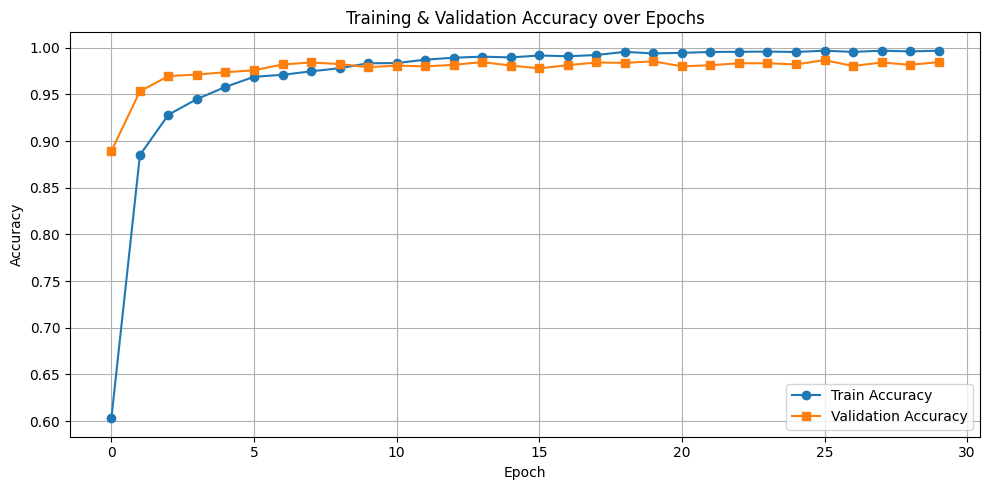

In [ ]:
train_accs = np.load(TRAIN_ACCS_FILE)
val_accs = np.load(VAL_ACCS_FILE)

plt.figure(figsize=(10, 5))
plt.plot(train_accs, label="Train Accuracy", marker='o')
plt.plot(val_accs, label="Validation Accuracy", marker='s')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training & Validation Accuracy over Epochs")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# Set random seed
torch.manual_seed(SEED)

_, test_dataset = prepare_datasets(DATASET_PATH, seed=SEED)
class_names = test_dataset.subset.dataset.classes

def evaluate_model(model_file, test_dataset):
    # Load test set
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    # Load model
    model = timm.create_model('resnet50', pretrained=False, num_classes=NUM_CLASSES)
    model.load_state_dict(torch.load(model_file, map_location=DEVICE))
    model.eval().to(DEVICE)

    # Collect predictions
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return all_preds, all_labels


def plot_confusion_matrix(class_names, all_labels, all_preds, title):
    # Compute confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    # Plot
    fig, ax = plt.subplots(figsize=(12, 10))
    disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
    plt.title(title)
    plt.tight_layout()
    plt.show()

In [6]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset)

# Classification Report
print("\nClassification Report:")
original_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      0.994     0.988     0.991       160
     Airport      0.987     0.981     0.984       160
       Beach      1.000     0.994     0.997       160
        City      0.981     0.988     0.984       160
      Desert      0.987     0.963     0.975       160
      Forest      0.987     0.975     0.981       160
   Grassland      0.981     0.981     0.981       160
     Highway      0.988     0.994     0.991       160
        Lake      0.987     0.981     0.984       160
    Mountain      0.952     0.994     0.972       160
     Parking      1.000     0.988     0.994       160
        Port      0.981     0.981     0.981       160
     Railway      0.975     0.981     0.978       160
 Residential      0.994     1.000     0.997       160
       River      0.988     0.994     0.991       160

    accuracy                          0.985      2400
   macro avg      0.986     0.985     0.985      2400
we

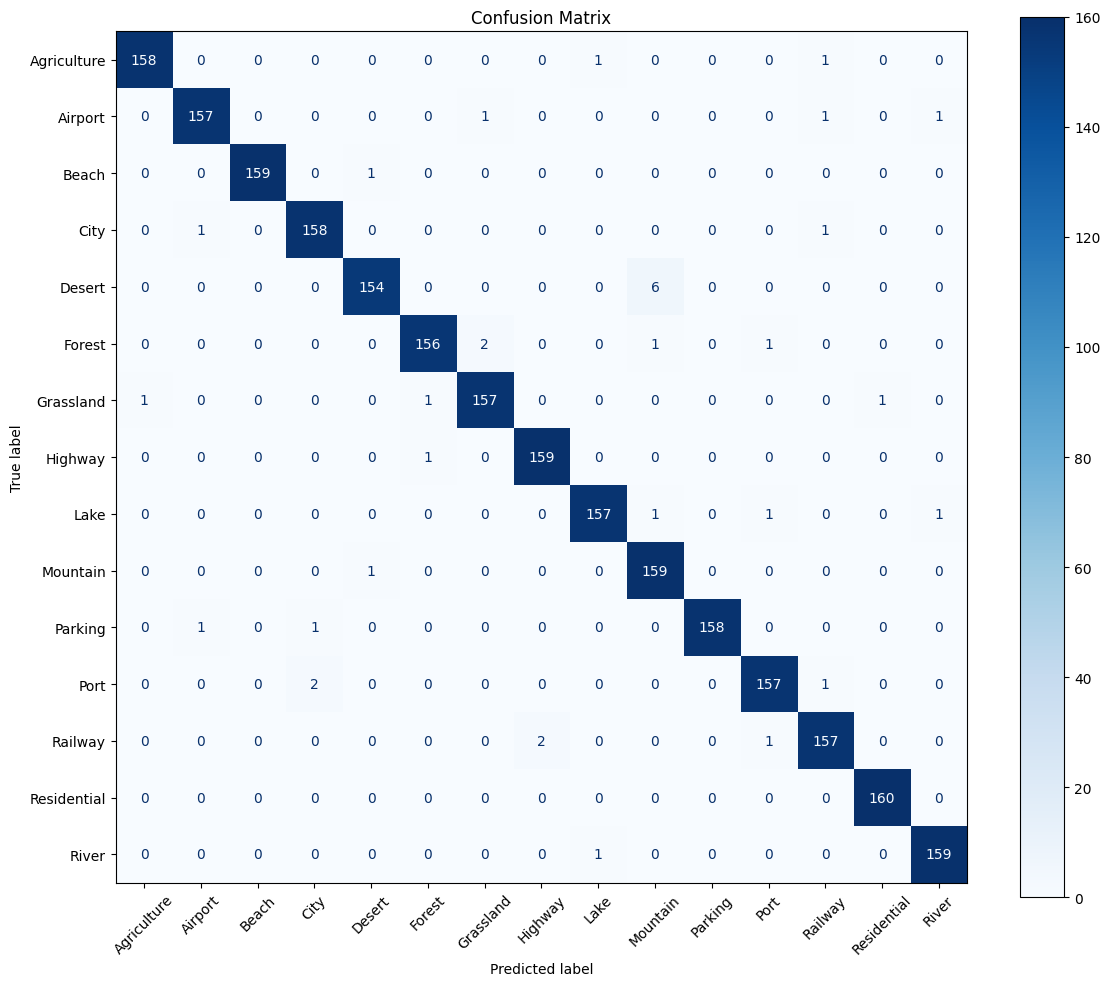

In [7]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

In [8]:
from image_preprocess import MyDataset
from utils.dataset_utils import get_blur_transform, get_noise_transform, get_patch_transform

raw_test_subset = test_dataset.subset  
test_dataset_patch = MyDataset(raw_test_subset, get_patch_transform())
test_dataset_blur  = MyDataset(raw_test_subset, get_blur_transform())
test_dataset_noise = MyDataset(raw_test_subset, get_noise_transform())

In [9]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset_patch)

# Classification Report
print("\nClassification Report:")
patch_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      0.981     0.988     0.984       160
     Airport      0.969     0.988     0.978       160
       Beach      0.994     0.981     0.987       160
        City      0.940     0.981     0.960       160
      Desert      0.994     0.975     0.984       160
      Forest      0.975     0.981     0.978       160
   Grassland      0.994     0.963     0.978       160
     Highway      0.987     0.981     0.984       160
        Lake      0.975     0.981     0.978       160
    Mountain      0.964     0.994     0.978       160
     Parking      0.987     0.975     0.981       160
        Port      0.981     0.981     0.981       160
     Railway      0.974     0.931     0.952       160
 Residential      0.988     1.000     0.994       160
       River      0.981     0.981     0.981       160

    accuracy                          0.979      2400
   macro avg      0.979     0.979     0.979      2400
we

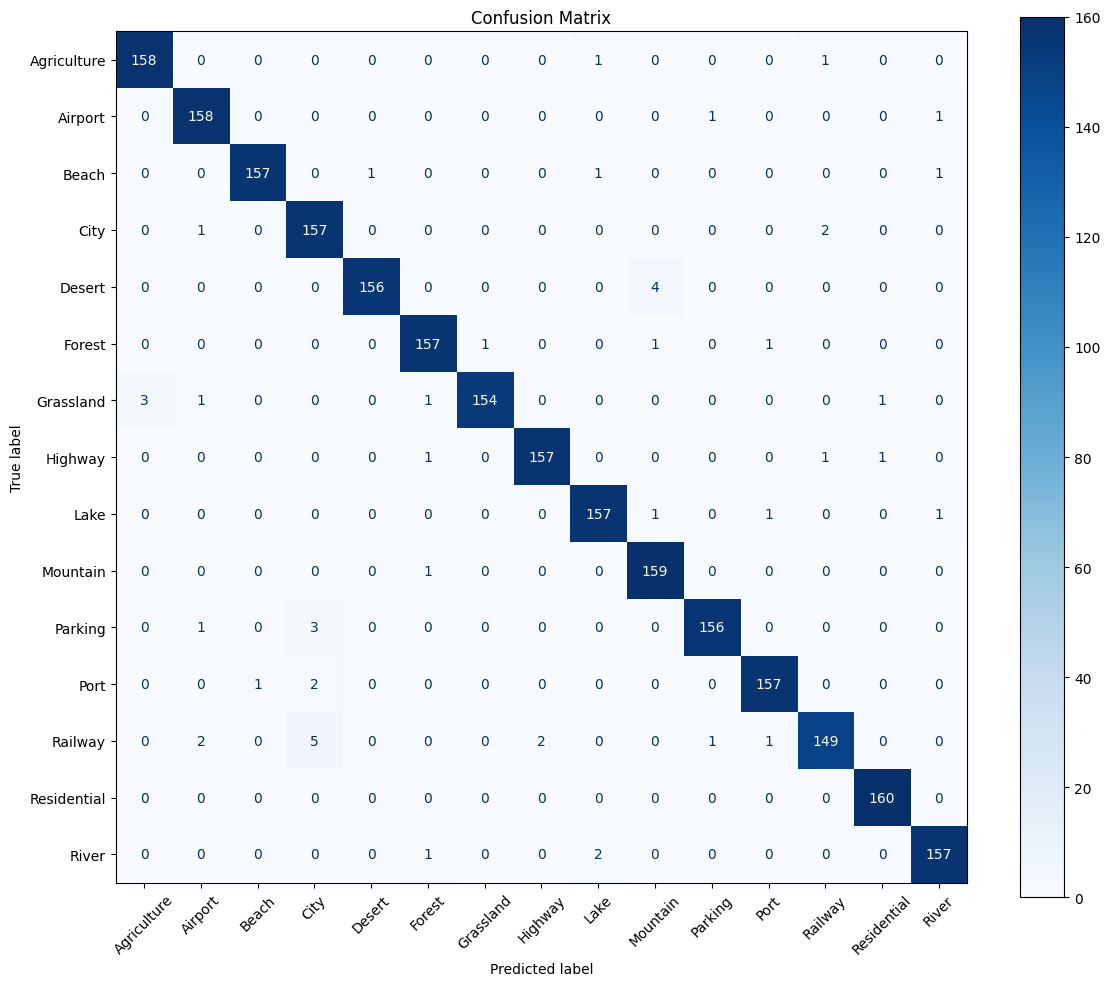

In [10]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

In [11]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset_blur)

# Classification Report
print("\nClassification Report:")
blur_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      1.000     0.738     0.849       160
     Airport      0.789     0.844     0.816       160
       Beach      0.831     0.981     0.900       160
        City      0.861     0.850     0.855       160
      Desert      0.755     0.981     0.853       160
      Forest      0.957     0.838     0.893       160
   Grassland      0.807     0.912     0.856       160
     Highway      0.856     0.894     0.875       160
        Lake      0.923     0.969     0.945       160
    Mountain      0.939     0.869     0.903       160
     Parking      0.986     0.894     0.938       160
        Port      0.965     0.869     0.914       160
     Railway      0.941     0.700     0.803       160
 Residential      0.851     0.925     0.886       160
       River      0.906     0.963     0.933       160

    accuracy                          0.882      2400
   macro avg      0.891     0.882     0.881      2400
we

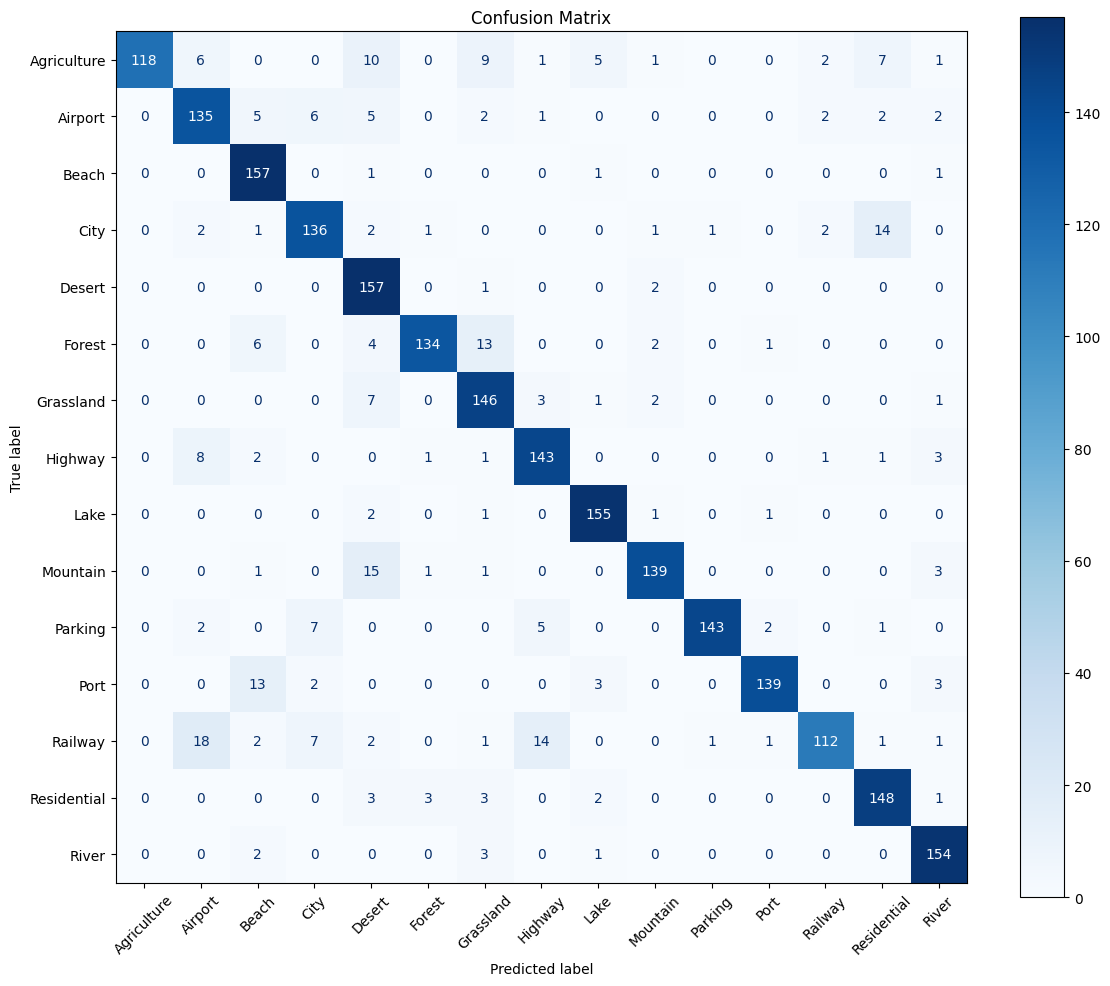

In [12]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

In [13]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset_noise)

# Classification Report
print("\nClassification Report:")
noise_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      0.980     0.619     0.759       160
     Airport      0.538     0.919     0.679       160
       Beach      0.909     0.688     0.783       160
        City      0.711     0.769     0.739       160
      Desert      0.870     0.544     0.669       160
      Forest      0.413     0.975     0.580       160
   Grassland      0.459     0.738     0.566       160
     Highway      0.941     0.900     0.920       160
        Lake      0.950     0.356     0.518       160
    Mountain      0.628     0.769     0.691       160
     Parking      0.899     0.950     0.924       160
        Port      0.984     0.750     0.851       160
     Railway      0.953     0.762     0.847       160
 Residential      1.000     0.350     0.519       160
       River      0.938     0.662     0.777       160

    accuracy                          0.717      2400
   macro avg      0.812     0.717     0.721      2400
we

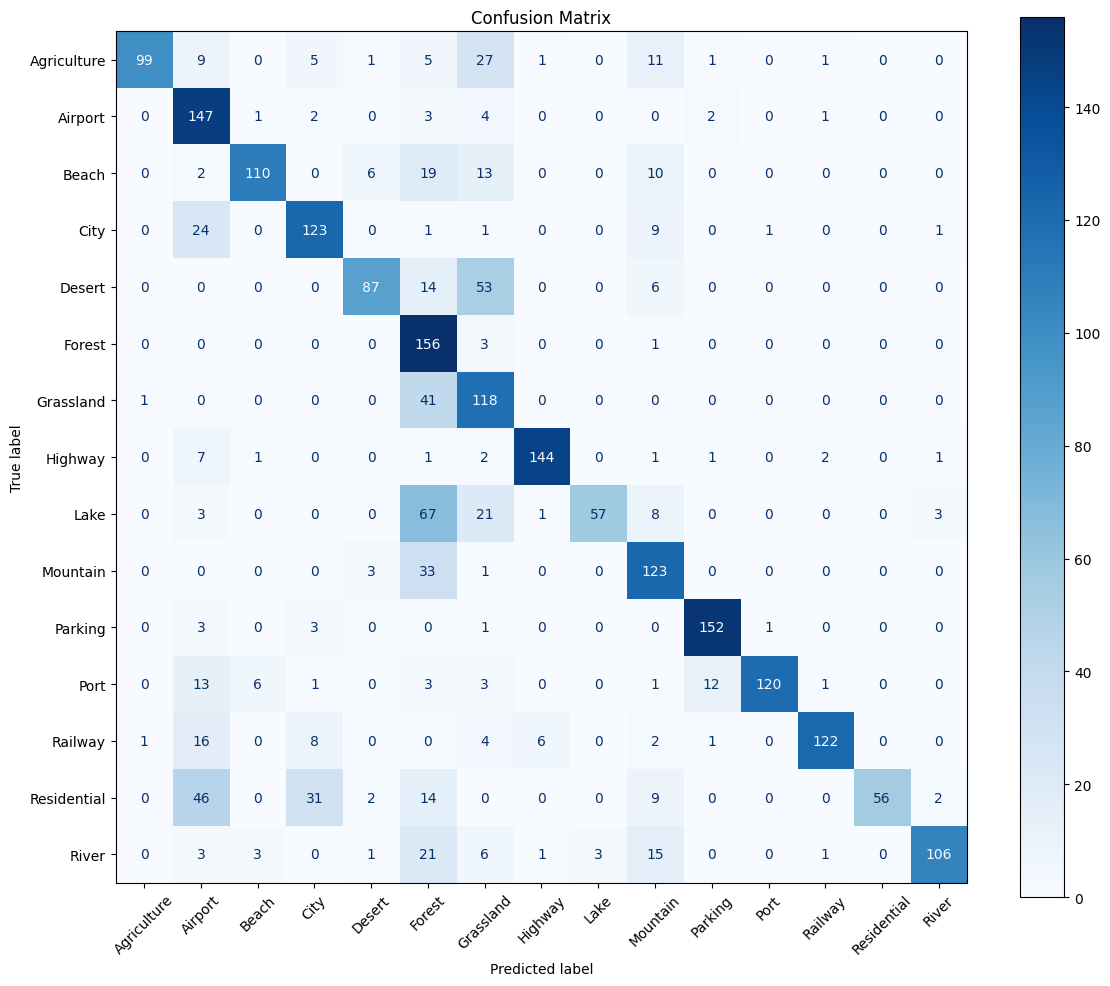

In [14]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

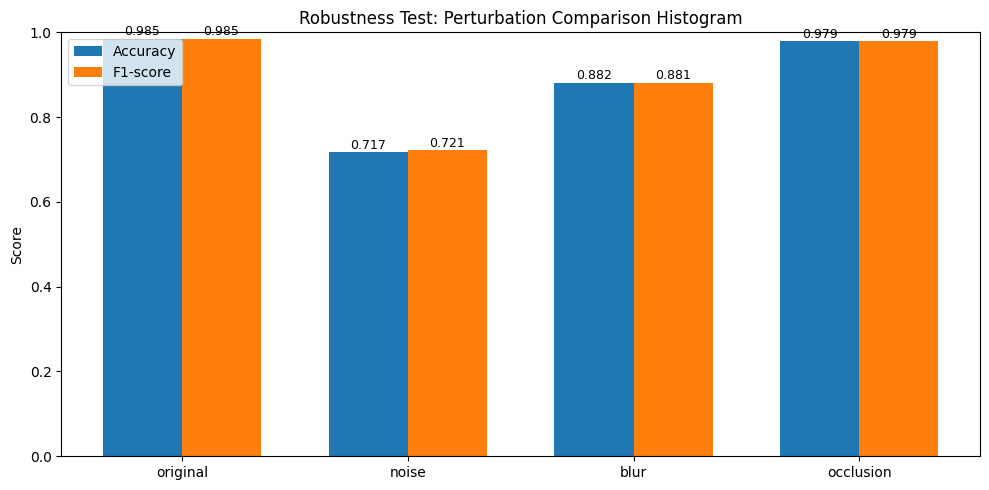

In [15]:
reports = {
    "original": original_classification_report,
    "noise": noise_classification_report,
    "blur": blur_classification_report,
    "occlusion": patch_classification_report
}

# Prepare data
perturbations = ["original", "noise", "blur", "occlusion"]
accuracies = [reports[p]['accuracy'] for p in perturbations]
f1_scores = [reports[p]['macro avg']['f1-score'] for p in perturbations]

# Set bar positions
x = range(len(perturbations))
width = 0.35

# Plot
plt.figure(figsize=(10, 5))
plt.bar([i - width/2 for i in x], accuracies, width=width, label='Accuracy')
plt.bar([i + width/2 for i in x], f1_scores, width=width, label='F1-score')

plt.xticks(ticks=x, labels=perturbations)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Robustness Test: Perturbation Comparison Histogram")
plt.legend()
for i in range(len(perturbations)):
    plt.text(i - width/2, accuracies[i] + 0.001, f"{accuracies[i]:.3f}", ha='center', va='bottom', fontsize=9)
    plt.text(i + width/2, f1_scores[i] + 0.001, f"{f1_scores[i]:.3f}", ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()
